In [2]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats

## Vitis HLS, 101 kernels, GPT-4.1, k=1

In [ ]:
# Load data
df_vitis_gpt_41_k1 = pd.read_csv('vitis_gpt-4.1_k1.csv')

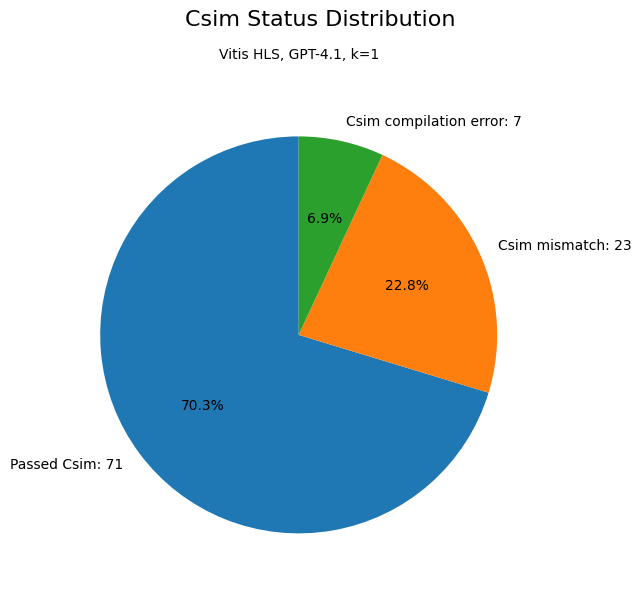

In [42]:
# Csim pie chart
status_counts = df_vitis_gpt_41_k1['status'].value_counts()
custom_labels = ['Passed Csim', 'Csim mismatch', 'Csim compilation error']

# Create labels with counts directly
labels_with_counts = [f'{label}: {count}' for label, count in zip(custom_labels, status_counts.values)]

fig, ax = plt.subplots(figsize=(7, 6))
ax.pie(
    status_counts.values,
    labels=labels_with_counts,
    autopct='%1.1f%%',
    startangle=90
)

fig.suptitle('Csim Status Distribution', fontsize=16, y=0.98)
plt.title('Vitis HLS, GPT-4.1, k=1', fontsize=10, pad=20)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3225837/318159141.py:38: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


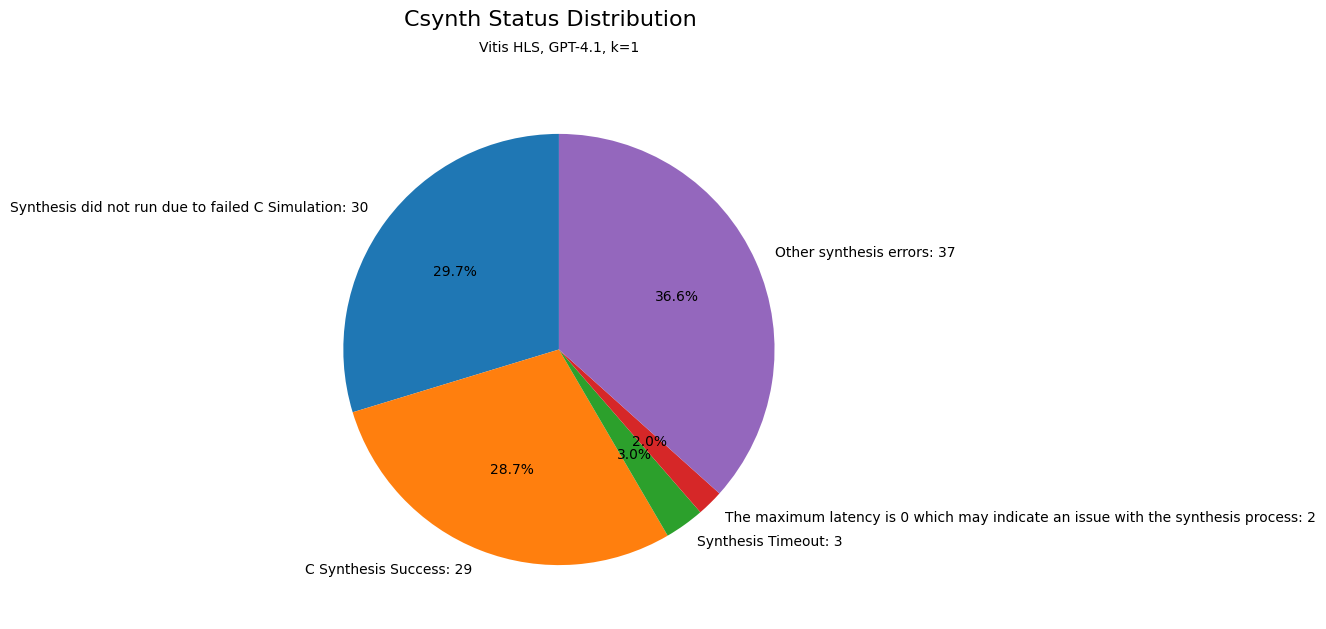

In [41]:
# Csynth pie chart
import pandas as pd

# Get your value counts
status_counts = df_vitis_gpt_41_k1['synth_errors'].value_counts()

# Define threshold - group categories with only 1 occurrence
threshold = 1
mask = status_counts <= threshold

# Sum the counts of small categories
other_count = status_counts[mask].sum()

# Filter out the small categories
main_counts = status_counts[~mask]

# Add the 'Other' category if there are any small categories
if other_count > 0:
    main_counts['Other'] = other_count

# Create the pie chart
fig, ax = plt.subplots(figsize=(7, 7))

custom_labels = ['Synthesis did not run due to failed C Simulation', 'C Synthesis Success', 'Synthesis Timeout', 'The maximum latency is 0 which may indicate an issue with the synthesis process', 'Other synthesis errors']

# Create labels with counts
labels_with_counts = [f'{label}: {count}' for label, count in zip(custom_labels, main_counts.values)]

ax.pie(
    main_counts.values,
    labels=labels_with_counts,
    autopct='%1.1f%%',
    startangle=90
)

fig.suptitle('Csynth Status Distribution', fontsize=16, y=0.98)
plt.title('Vitis HLS, GPT-4.1, k=1', fontsize=10, pad=20)
plt.tight_layout()
plt.show()


In [11]:
# csim_status = df_vitis_gpt_41_k1.groupby(['model', 'status'])['model'].count().unstack('status').fillna(0)

# csim_status.plot(kind='bar', stacked=True)

## Vitis HLS, 101 kernels, GPT-4.1-mini, k=10

In [4]:
# Load data
df_vitis_gpt_41_mini_k10 = pd.read_csv('vitis_gpt-4.1-mini_k10.csv')

# Function to calculate pass@k rate for Csim only
def calculate_csim_pass_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for Csim only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for Csim
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['status']:
            if isinstance(status, str) and 'passed' in status.lower():
                passed = True
                break
            elif str(status) == 'Passed Csim':
                passed = True
                break
        
        results.append(passed)
    
    return sum(results) / len(results) if results else 0

# Function to calculate pass@k rate for C synthesis
def calculate_synth_pass_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for synthesis - what fraction of kernels have at least one solution
    in iterations/attempts 1 through k that both passed status and has no synthesis errors
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for synthesis
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        # If there's no data for this kernel within iterations/attempts 1-k, consider it a fail
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed both criteria
        passed = False
        for _, row in kernel_subset.iterrows():
            status_pass = False
            synth_pass = False
            
            # Check status column
            if isinstance(row['status'], str) and 'passed' in row['status'].lower():
                status_pass = True
            elif str(row['status']) == 'Passed Csim':  # Or whatever exact string indicates success
                status_pass = True
                
            # Check synth_errors column
            if row['synth_errors'] == '-':
                synth_pass = True
                
            # Both conditions must be met
            if status_pass and synth_pass:
                passed = True
                break
        
        results.append(passed)
    
    # Return the fraction of kernels that passed
    return sum(results) / len(results) if results else 0


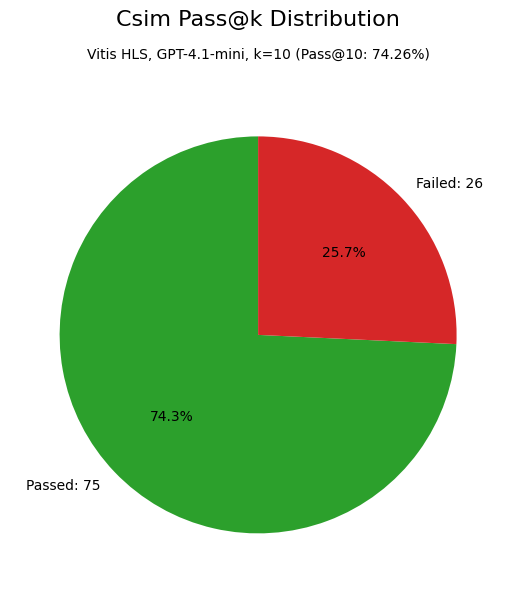

In [11]:
# CSim pass@k pie chart

# Create a new dataframe that checks if any iteration of each kernel passed
passed_kernels = df_vitis_gpt_41_mini_k10.groupby('kernel')['status'].apply(
    lambda x: 'Passed' if 'passed' in x.str.lower().values else 'Failed'
).reset_index()

# Count the passed vs failed kernels
passk_counts = passed_kernels['status'].value_counts()

# Create the pie chart
fig, ax = plt.subplots(figsize=(7, 6))

# Create labels with counts
labels_with_counts = [f'{label}: {count}' for label, count in zip(passk_counts.index, passk_counts.values)]

ax.pie(
    passk_counts.values,
    labels=labels_with_counts,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#2ca02c', '#d62728'] if 'Passed' in passk_counts.index and 'Failed' in passk_counts.index else None  # Green for passed, red for failed
)

# Calculate the actual pass@k rate for the title
total_kernels = len(passed_kernels['kernel'].unique())
passed_count = sum(passed_kernels['status'] == 'Passed')
pass_at_k_rate = passed_count / total_kernels

fig.suptitle('Csim Pass@k Distribution', fontsize=16, y=0.98)
plt.title(f'Vitis HLS, GPT-4.1-mini, k=10 (Pass@10: {pass_at_k_rate:.2%})', fontsize=10, pad=20)
plt.tight_layout()
plt.show()

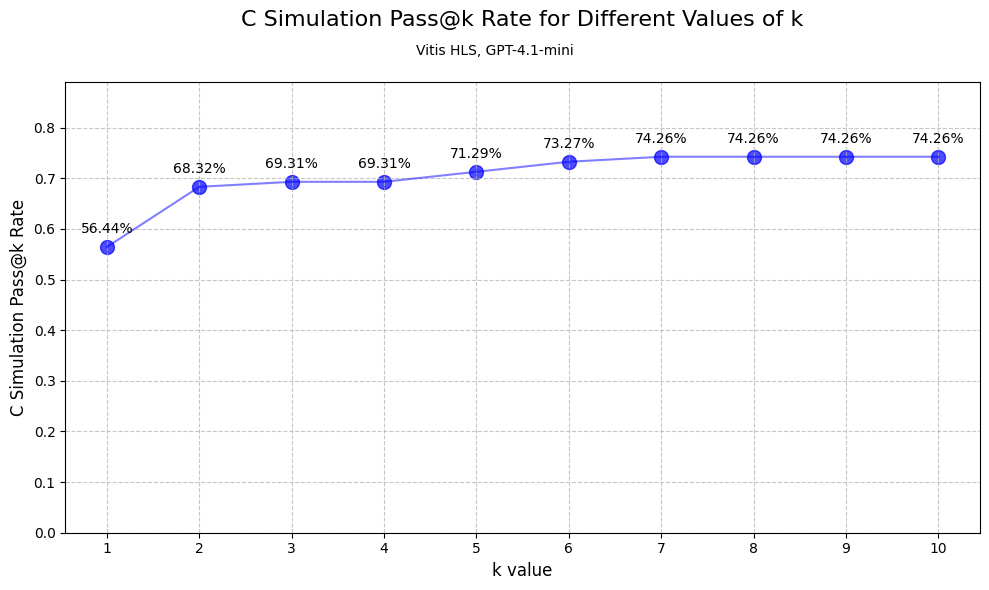

In [ ]:
# Csim pass@k for k=1-10
k_values = range(1, 11)
pass_rates = []

for k in attempt_values:
    pass_rate = calculate_csim_pass_at_k(df_vitis_gpt_41_mini_k10, k)
    pass_rates.append(pass_rate)

# Create the scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the points
ax.scatter(k_values, pass_rates, s=100, color='blue', alpha=0.7)

# Add a line connecting the points
ax.plot(k_values, pass_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center')

# Customize the plot
ax.set_xlabel('k value', fontsize=12)
ax.set_ylabel('C Simulation Pass@k Rate', fontsize=12)
ax.set_title('C Simulation Pass@k Rate for Different Values of k', fontsize=16, pad=40)
ax.set_xticks(attempt_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.set_ylim(0, min(1.0, max(pass_rates) * 1.2) if pass_rates else 1.0)  # Set y-axis limit with some padding

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis HLS, GPT-4.1-mini', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


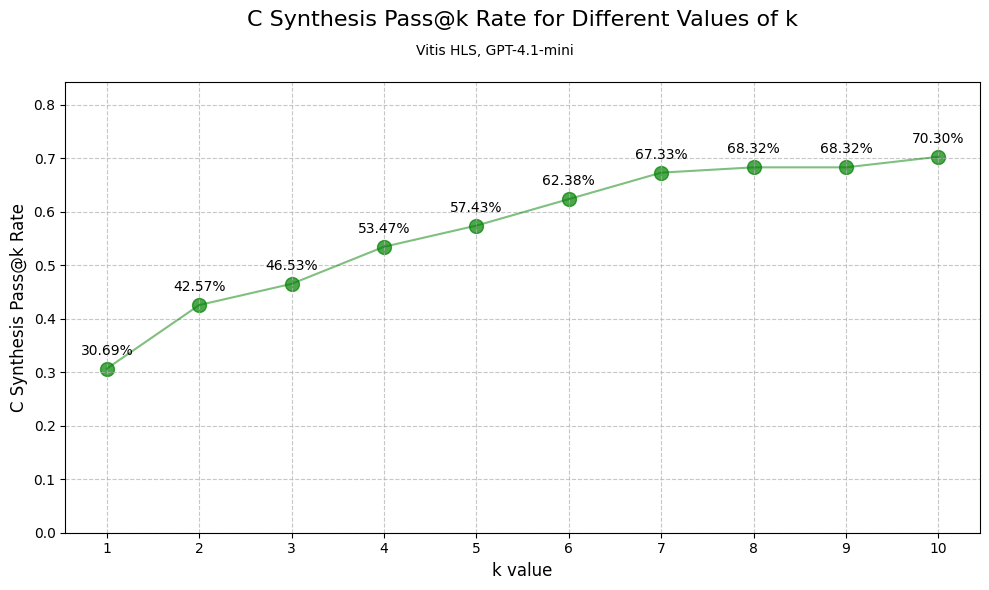

In [13]:
# Csynth pass@k for k=1-10
k_values = range(1, 11)
synth_pass_rates = []

for k in k_values:
    pass_rate = calculate_synth_pass_at_k(df_vitis_gpt_41_mini_k10, k)
    synth_pass_rates.append(pass_rate)

# Create the scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the points
ax.scatter(k_values, synth_pass_rates, s=100, color='green', alpha=0.7)

# Add a line connecting the points
ax.plot(k_values, synth_pass_rates, 'g-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, synth_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center')

# Customize the plot
ax.set_xlabel('k value', fontsize=12)
ax.set_ylabel('C Synthesis Pass@k Rate', fontsize=12)
ax.set_title('C Synthesis Pass@k Rate for Different Values of k', fontsize=16, pad=40)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.set_ylim(0, min(1.0, max(synth_pass_rates) * 1.2) if synth_pass_rates else 1.0)

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis HLS, GPT-4.1-mini', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


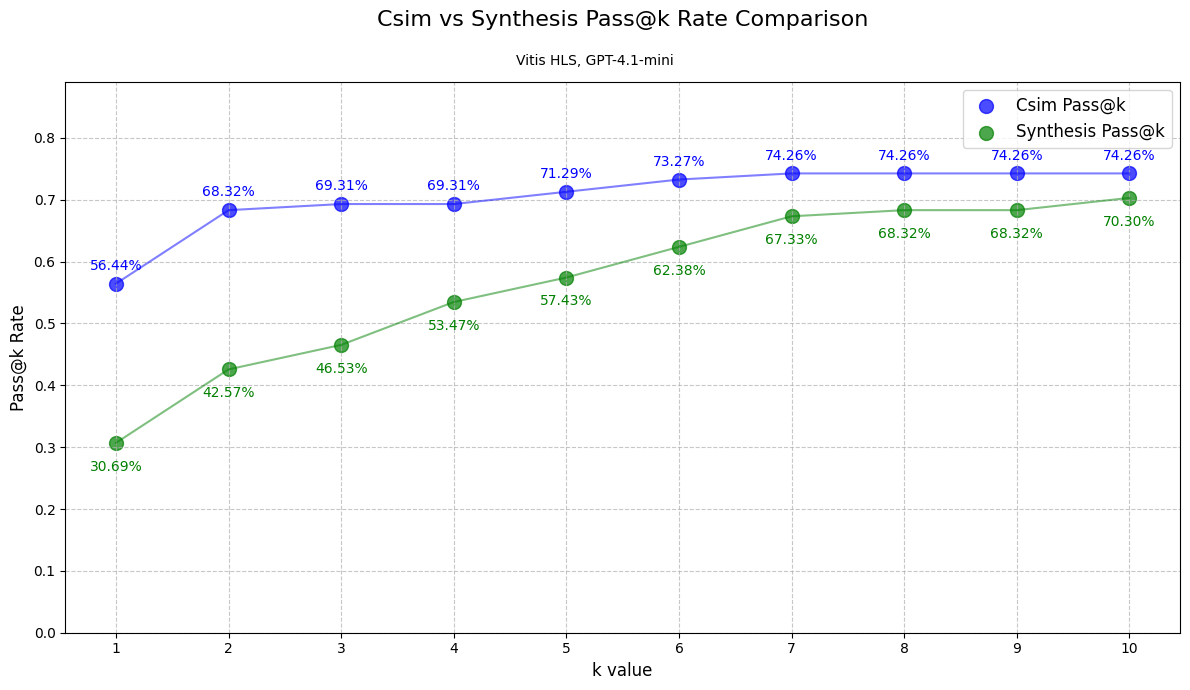

In [14]:


# Csim and Csynth pass@k for k=1-10
k_values = range(1, 11)
csim_pass_rates = []
synth_pass_rates = []

for k in k_values:
    csim_rate = calculate_csim_pass_at_k(df_vitis_gpt_41_mini_k10, k)
    synth_rate = calculate_synth_pass_at_k(df_vitis_gpt_41_mini_k10, k)
    csim_pass_rates.append(csim_rate)
    synth_pass_rates.append(synth_rate)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(k_values, csim_pass_rates, s=100, color='blue', alpha=0.7, label='Csim Pass@k')
ax.scatter(k_values, synth_pass_rates, s=100, color='green', alpha=0.7, label='Synthesis Pass@k')

# Add lines connecting the points
ax.plot(k_values, csim_pass_rates, 'b-', alpha=0.5)
ax.plot(k_values, synth_pass_rates, 'g-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, csim_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='blue')
                
for k, rate in zip(k_values, synth_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='green')

# Customize the plot
ax.set_xlabel('k value', fontsize=12)
ax.set_ylabel('Pass@k Rate', fontsize=12)
ax.set_title('Csim vs Synthesis Pass@k Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_pass_rates) if csim_pass_rates else 0, 
               max(synth_pass_rates) if synth_pass_rates else 0)
ax.set_ylim(0, min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis HLS, GPT-4.1-mini', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.ticker import MaxNLocator

# Process the dataframe as before
df_plot = df_vitis_gpt_41_mini_k10.copy()

# Process the latency column
def clean_latency(latency):
    if latency == '-' or pd.isna(latency):
        return np.nan
    try:
        return float(latency)
    except (ValueError, TypeError):
        return np.nan

df_plot['latency_numeric'] = df_plot['latency'].apply(clean_latency)

# Filter to only include passing results
def is_passing_result(row):
    # Check Csim status
    status_pass = False
    if isinstance(row['status'], str) and 'passed' in row['status'].lower():
        status_pass = True
    elif str(row['status']) == 'Passed Csim':
        status_pass = True
        
    # Check Csynth errors
    synth_pass = False
    if row['synth_errors'] == '-':
        synth_pass = True
        
    # Both conditions must be met
    return status_pass and synth_pass

df_passing = df_plot[df_plot.apply(is_passing_result, axis=1)]

# Get unique kernels
unique_kernels = df_passing['kernel'].unique()

# Create a multi-page plot (one plot per kernel)
for kernel in unique_kernels:
    # Get data for this kernel
    kernel_data = df_passing[df_passing['kernel'] == kernel]
    
    # Skip if no valid latency data
    if kernel_data['latency_numeric'].isna().all():
        continue
    
    # Sort by iteration to ensure lines connect in the right order
    kernel_data = kernel_data.sort_values('iteration')
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot the points
    ax.scatter(kernel_data['iteration'], kernel_data['latency_numeric'], 
               s=80, color='purple', alpha=0.7)
    
    # Extract valid iteration and latency pairs
    valid_iterations = []
    valid_latencies = []
    
    for _, row in kernel_data.iterrows():
        if not np.isnan(row['latency_numeric']):
            valid_iterations.append(row['iteration'])
            valid_latencies.append(row['latency_numeric'])
    
    # Plot a single line connecting all valid points in order
    if valid_iterations:
        ax.plot(valid_iterations, valid_latencies, 'purple', alpha=0.3, linestyle='-')
    
    # Add data labels
    for i, row in kernel_data.iterrows():
        if not np.isnan(row['latency_numeric']):
            ax.annotate(f"{int(row['latency_numeric'])}", 
                       (row['iteration'], row['latency_numeric']),
                       textcoords="offset points", 
                       xytext=(0, 10), 
                       ha='center',
                       fontsize=9)
    
    # Customize the plot
    ax.set_xlabel('Iteration', fontsize=12)
    ax.set_ylabel('Latency', fontsize=12)
    ax.set_title(f'Latency vs Iteration for Kernel: {kernel}', fontsize=14)
    
    # Set fixed axis limits
    ax.set_xlim(0.5, 10.5)  # From 1-10 with a small buffer on each side
    
    # Set y-axis to start at 0, with a reasonable upper limit
    max_latency = kernel_data['latency_numeric'].max()
    if not np.isnan(max_latency):
        ax.set_ylim(0, max_latency * 1.2)  # Add 20% padding at the top
    else:
        ax.set_ylim(0, 100)  # Default if no valid data
    
    # Set x-axis to integer ticks only
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    
    # Add grid
    ax.grid(True, linestyle='--', alpha=0.7)
    
    # Add subtitle
    plt.figtext(0.5, 0.01, 'Vitis GPT-4.1-mini (Passing Results Only)', fontsize=10, ha='center')
    
    plt.tight_layout()
    plt.show()


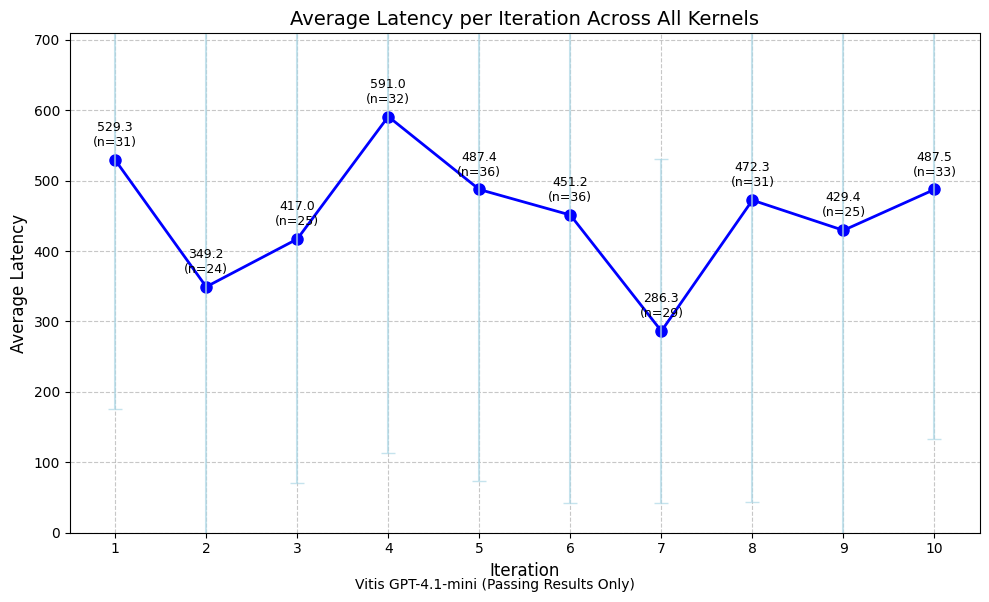

In [15]:
# Process the dataframe as before
df_plot = df_vitis_gpt_41_mini_k10.copy()

# Process the latency column
def clean_latency(latency):
    if latency == '-' or pd.isna(latency):
        return np.nan
    try:
        return float(latency)
    except (ValueError, TypeError):
        return np.nan

df_plot['latency_numeric'] = df_plot['latency'].apply(clean_latency)

# Filter to only include passing results
def is_passing_result(row):
    # Check Csim status
    status_pass = False
    if isinstance(row['status'], str) and 'passed' in row['status'].lower():
        status_pass = True
    elif str(row['status']) == 'Passed Csim':
        status_pass = True
        
    # Check Csynth errors
    synth_pass = False
    if row['synth_errors'] == '-':
        synth_pass = True
        
    # Both conditions must be met
    return status_pass and synth_pass

df_passing = df_plot[df_plot.apply(is_passing_result, axis=1)]

# Calculate average latency for each iteration across all kernels
avg_latency_by_iteration = df_passing.groupby('iteration')['latency_numeric'].mean()
std_latency_by_iteration = df_passing.groupby('iteration')['latency_numeric'].std()
count_by_iteration = df_passing.groupby('iteration')['latency_numeric'].count()

# Create a new figure
plt.figure(figsize=(10, 6))

# Plot the average latency
plt.plot(avg_latency_by_iteration.index, avg_latency_by_iteration.values, 
         'o-', color='blue', linewidth=2, markersize=8, label='Average Latency')

# Optionally add error bars for standard deviation
plt.errorbar(avg_latency_by_iteration.index, avg_latency_by_iteration.values, 
             yerr=std_latency_by_iteration.values, fmt='none', ecolor='lightblue', 
             elinewidth=1.5, capsize=5, alpha=0.7)

# Add data labels with both average value and sample count
for i, (avg, count) in enumerate(zip(avg_latency_by_iteration, count_by_iteration)):
    iteration = avg_latency_by_iteration.index[i]
    plt.annotate(f'{avg:.1f}\n(n={count})', 
                 (iteration, avg),
                 textcoords="offset points", 
                 xytext=(0, 10), 
                 ha='center',
                 fontsize=9)

# Customize the plot
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Average Latency', fontsize=12)
plt.title('Average Latency per Iteration Across All Kernels', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)

# Set fixed axis limits
plt.xlim(0.5, 10.5)  # From 1-10 with a small buffer on each side
plt.ylim(0, avg_latency_by_iteration.max() * 1.2)  # Start at 0, go to max+20%

# Set x-axis to integer ticks
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

# Add subtitle
plt.figtext(0.5, 0.01, 'Vitis GPT-4.1-mini (Passing Results Only)', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


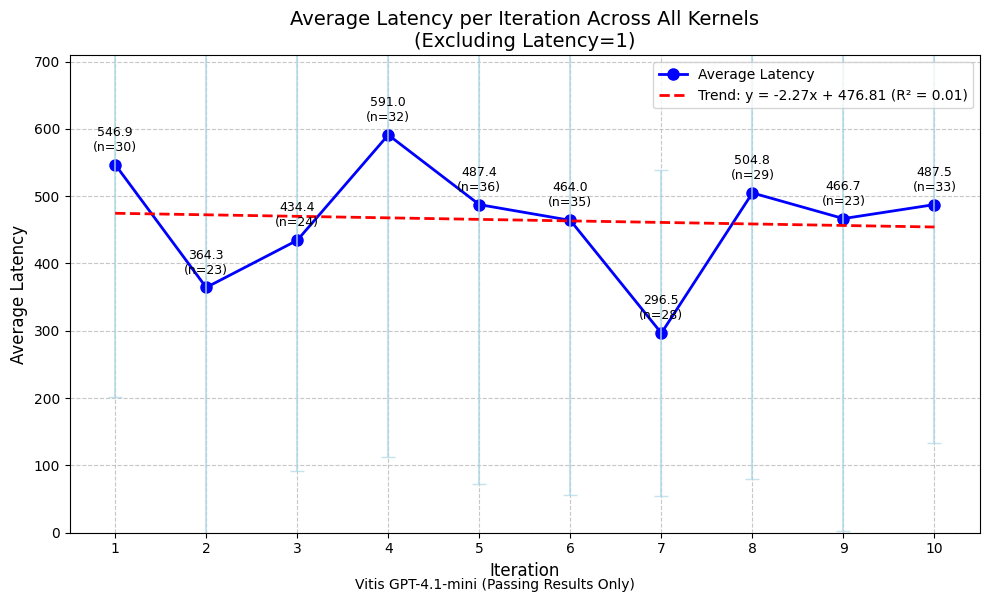

In [16]:
# Process the dataframe as before
df_plot = df_vitis_gpt_41_mini_k10.copy()

# Process the latency column
def clean_latency(latency):
    if latency == '-' or pd.isna(latency):
        return np.nan
    try:
        return float(latency)
    except (ValueError, TypeError):
        return np.nan

df_plot['latency_numeric'] = df_plot['latency'].apply(clean_latency)

# Filter to only include passing results
def is_passing_result(row):
    # Check Csim status
    status_pass = False
    if isinstance(row['status'], str) and 'passed' in row['status'].lower():
        status_pass = True
    elif str(row['status']) == 'Passed Csim':
        status_pass = True
        
    # Check Csynth errors
    synth_pass = False
    if row['synth_errors'] == '-':
        synth_pass = True
        
    # Both conditions must be met
    return status_pass and synth_pass

df_passing = df_plot[df_plot.apply(is_passing_result, axis=1)]

# Additional filter: exclude entries with latency=1
df_passing = df_passing[df_passing['latency_numeric'] != 1]

# Calculate average latency for each iteration across all kernels
avg_latency_by_iteration = df_passing.groupby('iteration')['latency_numeric'].mean()
std_latency_by_iteration = df_passing.groupby('iteration')['latency_numeric'].std()
count_by_iteration = df_passing.groupby('iteration')['latency_numeric'].count()

# Create a new figure
plt.figure(figsize=(10, 6))

# Plot the average latency
plt.plot(avg_latency_by_iteration.index, avg_latency_by_iteration.values, 
         'o-', color='blue', linewidth=2, markersize=8, label='Average Latency')

# Optionally add error bars for standard deviation
plt.errorbar(avg_latency_by_iteration.index, avg_latency_by_iteration.values, 
             yerr=std_latency_by_iteration.values, fmt='none', ecolor='lightblue', 
             elinewidth=1.5, capsize=5, alpha=0.7)

# Add a line of best fit
# First, prepare the data for the line of best fit (removing NaN values)
x_data = []
y_data = []
for i, val in zip(avg_latency_by_iteration.index, avg_latency_by_iteration.values):
    if not np.isnan(val):
        x_data.append(i)
        y_data.append(val)

# Calculate the line of best fit if we have enough data points
if len(x_data) >= 2:  # Need at least 2 points for a line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
    
    # Create a line using the slope and intercept
    x_line = np.array([1, 10])  # Line from iteration 1 to 10
    y_line = slope * x_line + intercept
    
    # Plot the line of best fit
    plt.plot(x_line, y_line, 'r--', linewidth=2, 
             label=f'Trend: y = {slope:.2f}x + {intercept:.2f} (R² = {r_value**2:.2f})')

# Add data labels with both average value and sample count
for i, (avg, count) in enumerate(zip(avg_latency_by_iteration, count_by_iteration)):
    iteration = avg_latency_by_iteration.index[i]
    if not np.isnan(avg):
        plt.annotate(f'{avg:.1f}\n(n={count})', 
                    (iteration, avg),
                    textcoords="offset points", 
                    xytext=(0, 10), 
                    ha='center',
                    fontsize=9)

# Customize the plot
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Average Latency', fontsize=12)
plt.title('Average Latency per Iteration Across All Kernels\n(Excluding Latency=1)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)

# Set fixed axis limits
plt.xlim(0.5, 10.5)  # From 1-10 with a small buffer on each side
plt.ylim(0, avg_latency_by_iteration.max() * 1.2 if not avg_latency_by_iteration.empty else 100)  # Start at 0

# Set x-axis to integer ticks
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

# Add legend
plt.legend(loc='best')

# Add subtitle
plt.figtext(0.5, 0.01, 'Vitis GPT-4.1-mini (Passing Results Only)', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


## Vitis HLS, 101 kernels, GPT-4.1-mini, k=1, 10 feedback attempts

In [6]:
df_vitis_gpt_41_mini_k1_attempts10 = pd.read_csv('vitis_gpt-4.1-mini_k1_attempts10.csv')

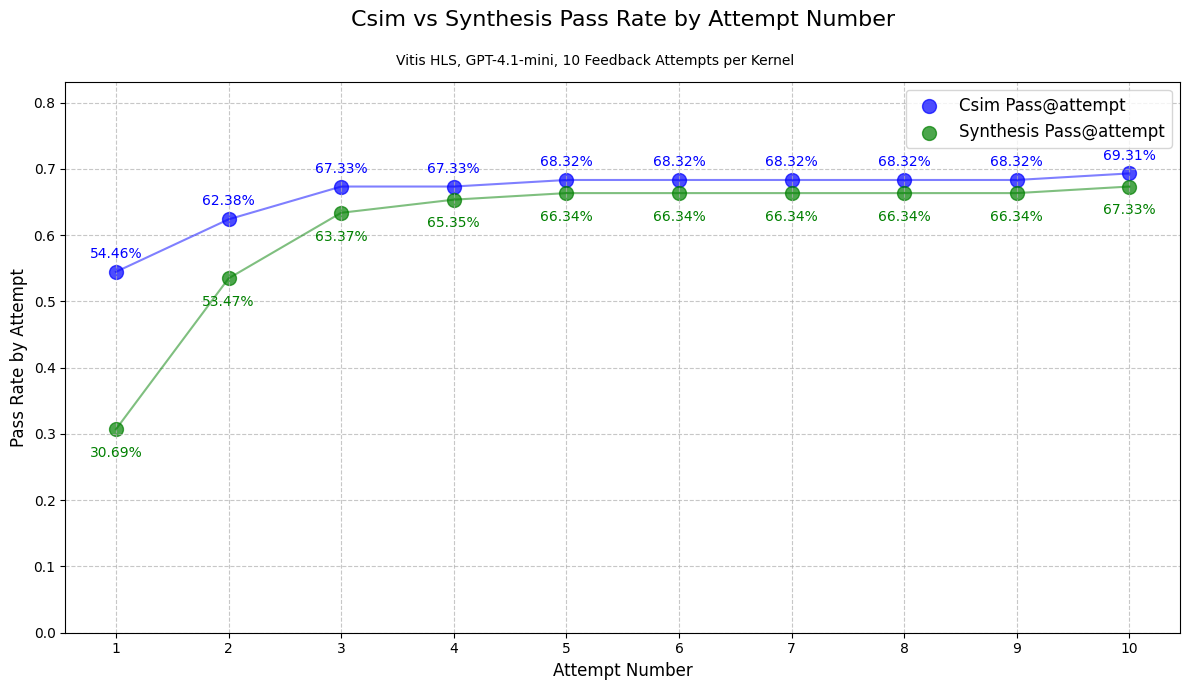

In [ ]:
# Csim and Csynth pass@k for attempts=1-10
attempt_values = range(1, 11)
csim_pass_rates = []
synth_pass_rates = []

for k in attempt_values:
    csim_rate = calculate_csim_pass_at_k(df_vitis_gpt_41_mini_k1_attempts10, k, "attempts")
    synth_rate = calculate_synth_pass_at_k(df_vitis_gpt_41_mini_k1_attempts10, k, "attempts")
    csim_pass_rates.append(csim_rate)
    synth_pass_rates.append(synth_rate)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(attempt_values, csim_pass_rates, s=100, color='blue', alpha=0.7, label='Csim Pass@attempt')
ax.scatter(attempt_values, synth_pass_rates, s=100, color='green', alpha=0.7, label='Synthesis Pass@attempt')

# Add lines connecting the points
ax.plot(attempt_values, csim_pass_rates, 'b-', alpha=0.5)
ax.plot(attempt_values, synth_pass_rates, 'g-', alpha=0.5)

# Add labels for each point
for k, rate in zip(attempt_values, csim_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='blue')
                
for k, rate in zip(attempt_values, synth_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='green')

# Customize the plot
ax.set_xlabel('Attempt Number', fontsize=12)
ax.set_ylabel('Pass Rate by Attempt', fontsize=12)
ax.set_title('Csim vs Synthesis Pass Rate by Attempt Number', fontsize=16, pad=40)
ax.set_xticks(attempt_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(csim_pass_rates) if csim_pass_rates else 0, 
               max(synth_pass_rates) if synth_pass_rates else 0)
ax.set_ylim(0, min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Vitis HLS, GPT-4.1-mini, 10 Feedback Attempts per Kernel', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


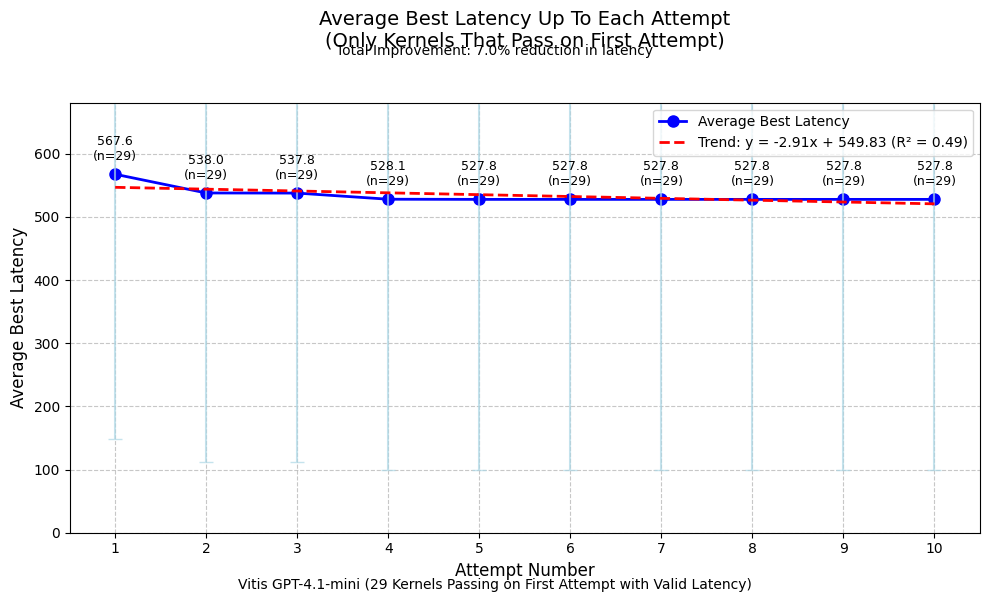

In [ ]:
# Process the dataframe as before
df_plot = df_vitis_gpt_41_mini_k1_attempts10.copy()  # Using the attempts dataframe

# Process the latency column
def clean_latency(latency):
    if latency == '-' or pd.isna(latency):
        return np.nan
    try:
        return float(latency)
    except (ValueError, TypeError):
        return np.nan

df_plot['latency_numeric'] = df_plot['latency'].apply(clean_latency)

# Filter to only include passing results
def is_passing_result(row):
    # Check Csim status
    status_pass = False
    if isinstance(row['status'], str) and 'passed' in row['status'].lower():
        status_pass = True
    elif str(row['status']) == 'Passed Csim':
        status_pass = True
        
    # Check Csynth errors
    synth_pass = False
    if row['synth_errors'] == '-':
        synth_pass = True
        
    # Both conditions must be met
    return status_pass and synth_pass

# Find kernels that pass on attempt 1
passing_kernels_attempt1 = df_plot[
    (df_plot['attempts'] == 1) & 
    df_plot.apply(is_passing_result, axis=1)
]['kernel'].unique()

# Filter dataframe to only include those kernels
df_passing_kernels = df_plot[df_plot['kernel'].isin(passing_kernels_attempt1)]

# Apply the passing results filter to get only successful runs
df_passing = df_passing_kernels[df_passing_kernels.apply(is_passing_result, axis=1)]

# Additional filter: exclude entries with latency=1
df_passing = df_passing[df_passing['latency_numeric'] != 1]

# Get the list of kernels that have valid latency data
kernels_with_valid_latency = df_passing[~pd.isna(df_passing['latency_numeric'])]['kernel'].unique()

# Filter to only include these kernels
df_passing = df_passing[df_passing['kernel'].isin(kernels_with_valid_latency)]

# Function to get best latency up to each attempt for each kernel
def get_best_latencies_by_attempt(df):
    best_latencies = {}
    max_attempt = int(df['attempts'].max())
    kernels = df['kernel'].unique()
    
    # Process each kernel
    for kernel in kernels:
        kernel_data = df[df['kernel'] == kernel].sort_values('attempts')
        
        # Initialize best latency for this kernel
        best_latency = float('inf')
        best_latencies[kernel] = {}
        
        # Track the best latency for each attempt
        for attempt in range(1, max_attempt + 1):
            # Get data for this attempt if it exists
            attempt_data = kernel_data[kernel_data['attempts'] == attempt]
            
            if not attempt_data.empty and not pd.isna(attempt_data['latency_numeric'].values[0]):
                current_latency = attempt_data['latency_numeric'].values[0]
                best_latency = min(best_latency, current_latency)
            
            # Store the best latency so far
            best_latencies[kernel][attempt] = best_latency if best_latency != float('inf') else np.nan
    
    return best_latencies, kernels

# Get best latencies for each kernel by attempt
best_latencies, kernels_tracked = get_best_latencies_by_attempt(df_passing)

# Convert to dataframe for easier analysis
best_latency_data = []
for kernel in kernels_tracked:
    # Check if kernel has valid data for the first attempt
    if 1 in best_latencies[kernel] and not pd.isna(best_latencies[kernel][1]):
        # Only include kernels with valid first attempt data
        for attempt in range(1, int(df_passing['attempts'].max()) + 1):
            if attempt in best_latencies[kernel]:
                latency = best_latencies[kernel][attempt]
                best_latency_data.append({'kernel': kernel, 'attempt': attempt, 'best_latency': latency})

best_latency_df = pd.DataFrame(best_latency_data)

# Make sure we have the same count for each attempt by checking and filtering
kernel_attempt_counts = best_latency_df.groupby('kernel').size()
kernels_with_all_attempts = kernel_attempt_counts[kernel_attempt_counts == int(df_passing['attempts'].max())].index
best_latency_df = best_latency_df[best_latency_df['kernel'].isin(kernels_with_all_attempts)]

# Calculate average of best latencies for each attempt
avg_best_latency_by_attempt = best_latency_df.groupby('attempt')['best_latency'].mean()
std_best_latency_by_attempt = best_latency_df.groupby('attempt')['best_latency'].std()
count_by_attempt = best_latency_df.groupby('attempt')['best_latency'].count()

# Verify we have the same count for all attempts
if count_by_attempt.nunique() != 1:
    print("Warning: Different counts for different attempts. First fixing the data.")
    
    # Get the kernels that appear in all attempts
    kernel_counts = best_latency_df.groupby('kernel')['attempt'].count()
    valid_kernels = kernel_counts[kernel_counts == count_by_attempt.index.max()].index
    
    # Filter to only include these kernels
    best_latency_df = best_latency_df[best_latency_df['kernel'].isin(valid_kernels)]
    
    # Recalculate the statistics
    avg_best_latency_by_attempt = best_latency_df.groupby('attempt')['best_latency'].mean()
    std_best_latency_by_attempt = best_latency_df.groupby('attempt')['best_latency'].std()
    count_by_attempt = best_latency_df.groupby('attempt')['best_latency'].count()

# Create a new figure
plt.figure(figsize=(10, 6))

# Plot the average best latency
plt.plot(avg_best_latency_by_attempt.index, avg_best_latency_by_attempt.values, 
         'o-', color='blue', linewidth=2, markersize=8, label='Average Best Latency')

# Optionally add error bars for standard deviation
plt.errorbar(avg_best_latency_by_attempt.index, avg_best_latency_by_attempt.values, 
             yerr=std_best_latency_by_attempt.values, fmt='none', ecolor='lightblue', 
             elinewidth=1.5, capsize=5, alpha=0.7)

# Add a line of best fit
# First, prepare the data for the line of best fit (removing NaN values)
x_data = []
y_data = []
for i, val in zip(avg_best_latency_by_attempt.index, avg_best_latency_by_attempt.values):
    if not np.isnan(val):
        x_data.append(i)
        y_data.append(val)

# Calculate the line of best fit if we have enough data points
if len(x_data) >= 2:  # Need at least 2 points for a line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
    
    # Create a line using the slope and intercept
    x_line = np.array([1, 10])  # Line from attempt 1 to 10
    y_line = slope * x_line + intercept
    
    # Plot the line of best fit
    plt.plot(x_line, y_line, 'r--', linewidth=2, 
             label=f'Trend: y = {slope:.2f}x + {intercept:.2f} (R² = {r_value**2:.2f})')

# Add data labels with average value and consistent sample count
sample_count = count_by_attempt.iloc[0]  # Should be the same for all attempts now
for i, avg in enumerate(avg_best_latency_by_attempt):
    attempt = avg_best_latency_by_attempt.index[i]
    if not np.isnan(avg):
        plt.annotate(f'{avg:.1f}\n(n={sample_count})', 
                    (attempt, avg),
                    textcoords="offset points", 
                    xytext=(0, 10), 
                    ha='center',
                    fontsize=9)

# Customize the plot
plt.xlabel('Attempt Number', fontsize=12)
plt.ylabel('Average Best Latency', fontsize=12)
plt.title('Average Best Latency Up To Each Attempt\n(Only Kernels That Pass on First Attempt)', fontsize=14, pad=40)
plt.grid(True, linestyle='--', alpha=0.7)

# Set fixed axis limits
plt.xlim(0.5, 10.5)  # From 1-10 with a small buffer on each side
plt.ylim(0, avg_best_latency_by_attempt.max() * 1.2 if not avg_best_latency_by_attempt.empty else 100)  # Start at 0

# Set x-axis to integer ticks
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

# Add legend
plt.legend(loc='best')

# Add subtitle
plt.figtext(0.5, 0.01, 
            f'Vitis GPT-4.1-mini ({sample_count} Kernels Passing on First Attempt with Valid Latency)', 
            fontsize=10, ha='center')

# Calculate the percentage improvement from attempt 1 to max attempt
if not avg_best_latency_by_attempt.empty and len(avg_best_latency_by_attempt) > 1:
    first_attempt_latency = avg_best_latency_by_attempt.iloc[0]
    last_attempt_latency = avg_best_latency_by_attempt.iloc[-1]
    percent_improvement = (first_attempt_latency - last_attempt_latency) / first_attempt_latency * 100
    
    # Add improvement annotation
    plt.figtext(0.5, 0.87, 
                f'Total Improvement: {percent_improvement:.1f}% reduction in latency', 
                fontsize=10, ha='center')

plt.tight_layout()
plt.show()


# Dynarapid, 30 Kernels, GPT-4.1-mini, k=10


In [5]:
# Function to calculate pass@k rate for Csim only
def calculate_has_dot_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for HasDot only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for hasDot
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['has_dot']:
            if status:
                passed = True
                break
            elif str(status) == 'TRUE':
                passed = True
                break
        
        results.append(passed)
    
    return sum(results) / len(results) if results else 0

# Function to calculate pass@k rate for Csim only
def calculate_has_dcp_at_k(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for hasDCP only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for hasDCP
    """
    results = []
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['has_dcp']:
            if status:
                passed = True
                break
            elif str(status) == 'TRUE':
                passed = True
                break
        
        results.append(passed)
    
    return sum(results) / len(results) if results else 0

In [11]:
df_dynarapid_gpt_41_mini_k10 = pd.read_csv('dynarapid_gpt-4.1-mini_k10.csv')

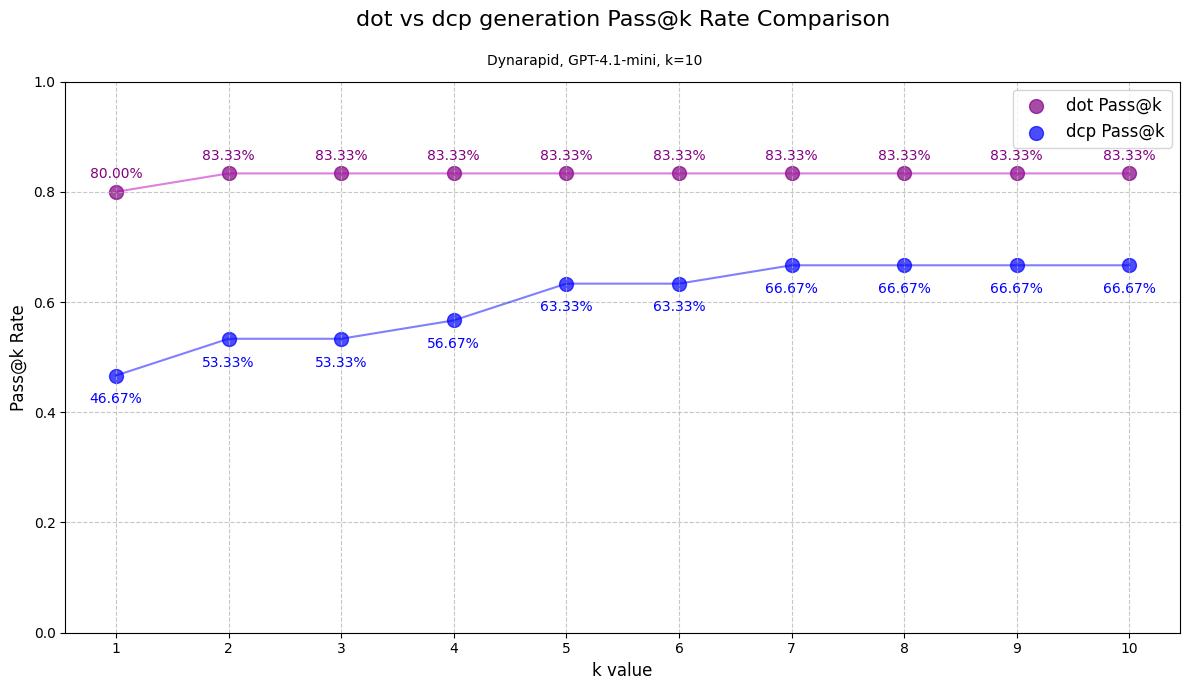

In [32]:
# HasDot and HasDCP
k_values = range(1, 11)
dot_pass_rates = []
dcp_pass_rates = []

for k in k_values:
    dot_rate = calculate_has_dot_at_k(df_dynarapid_gpt_41_mini_k10, k, "pass@k")
    dcp_rate = calculate_has_dcp_at_k(df_dynarapid_gpt_41_mini_k10, k, "pass@k")
    dot_pass_rates.append(dot_rate)
    dcp_pass_rates.append(dcp_rate)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(k_values, dot_pass_rates, s=100, color='purple', alpha=0.7, label='dot Pass@k')
ax.scatter(k_values, dcp_pass_rates, s=100, color='blue', alpha=0.7, label='dcp Pass@k')

# Add lines connecting the points
ax.plot(k_values, dot_pass_rates, 'm-', alpha=0.5)
ax.plot(k_values, dcp_pass_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(k_values, dot_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(k_values, dcp_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('k value', fontsize=12)
ax.set_ylabel('Pass@k Rate', fontsize=12)
ax.set_title('dot vs dcp generation Pass@k Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(dot_pass_rates) if dot_pass_rates else 0, 
               max(dcp_pass_rates) if dcp_pass_rates else 0)
ax.set_ylim(0, min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Dynarapid, GPT-4.1-mini, k=10', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


# Dynarapid, 30 Kernels, GPT-4.1-mini, k=1 attempts=10

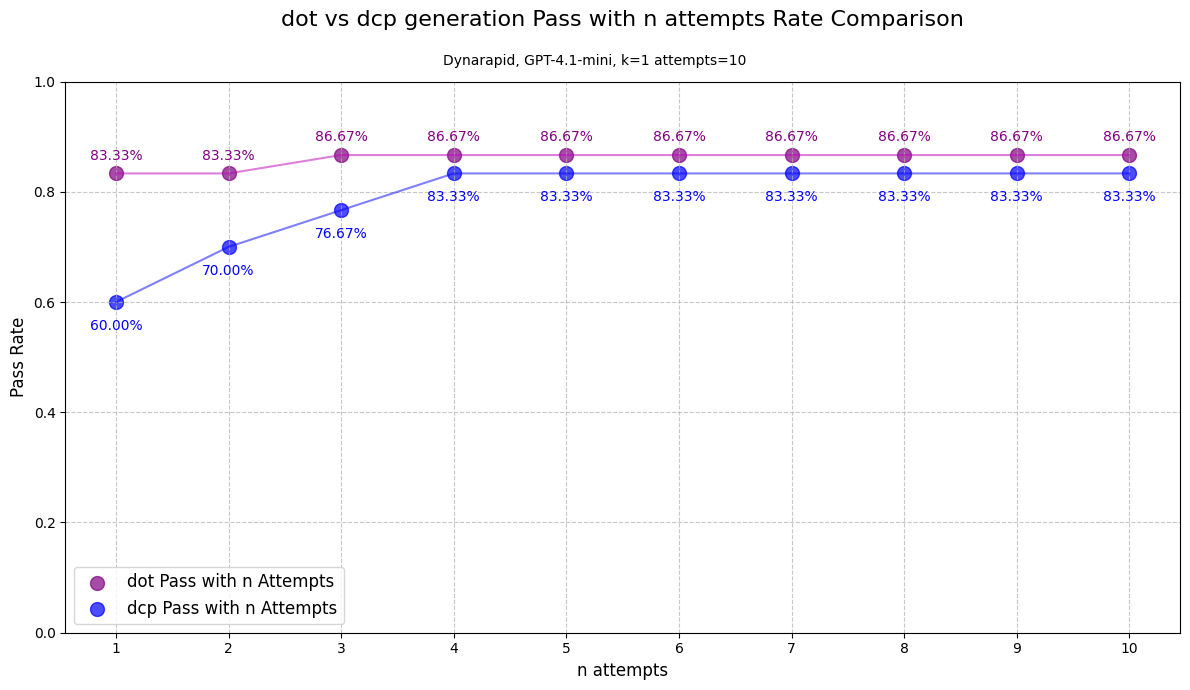

In [14]:
# HasDot and HasDCP
df_dynarapid_gpt_41_mini_k1_a10 = pd.read_csv('dynarapid_gpt-4.1-mini_k1_attempts10.csv')

attempt_values = range(1, 11)
dot_pass_rates = []
dcp_pass_rates = []

for k in attempt_values:
    dot_rate = calculate_has_dot_at_k(df_dynarapid_gpt_41_mini_k1_a10, k, "attempt")
    dcp_rate = calculate_has_dcp_at_k(df_dynarapid_gpt_41_mini_k1_a10, k, "attempt")
    dot_pass_rates.append(dot_rate)
    dcp_pass_rates.append(dcp_rate)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.scatter(attempt_values, dot_pass_rates, s=100, color='purple', alpha=0.7, label='dot Pass with n Attempts')
ax.scatter(attempt_values, dcp_pass_rates, s=100, color='blue', alpha=0.7, label='dcp Pass with n Attempts')

# Add lines connecting the points
ax.plot(attempt_values, dot_pass_rates, 'm-', alpha=0.5)
ax.plot(attempt_values, dcp_pass_rates, 'b-', alpha=0.5)

# Add labels for each point
for k, rate in zip(attempt_values, dot_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                color='purple')
                
for k, rate in zip(attempt_values, dcp_pass_rates):
    ax.annotate(f'{rate:.2%}', 
                (k, rate),
                textcoords="offset points", 
                xytext=(0, -20), 
                ha='center',
                color='blue')

# Customize the plot
ax.set_xlabel('n attempts', fontsize=12)
ax.set_ylabel('Pass Rate', fontsize=12)
ax.set_title('dot vs dcp generation Pass with n attempts Rate Comparison', fontsize=16, pad=40)
ax.set_xticks(attempt_values)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12)

# Set y-axis limit to include both lines with some padding
max_rate = max(max(dot_pass_rates) if dot_pass_rates else 0, 
               max(dcp_pass_rates) if dcp_pass_rates else 0)
ax.set_ylim(0, min(1.0, max_rate * 1.2))

# Add a subtitle
plt.figtext(0.5, 0.9, 'Dynarapid, GPT-4.1-mini, k=1 attempts=10', fontsize=10, ha='center')

plt.tight_layout()
plt.show()


# Dynarapid, 30 Kernels, GPT-4.1-mini, k=1 attempts=10

In [3]:
# Function to calculate pass@k rate for Csim only
def calculate_has_dot_per_kernel(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for HasDot only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for hasDot
    """
    kernel_ratios = {}
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        # print(kernel_data)
        results = []

        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['has_dot']:
            if status:
                passed = True
            elif str(status).lower() == 'true':
                passed = True
            else:
                passed = False
            results.append(passed)
        ratio = sum(results) / len(results) if results else 0
        kernel_ratios[kernel] = ratio

    return kernel_ratios

# Function to calculate pass@k rate for Csim only
def calculate_has_dcp_per_kernel(df, k_value, iteration_column='iteration'):
    """
    Calculate the pass@k rate for hasDCP only
    
    Parameters:
    df (DataFrame): DataFrame containing the data
    k_value (int): The k value to calculate pass@k for
    iteration_column (str): The name of the column containing iteration or attempt numbers
    
    Returns:
    float: The pass@k rate for hasDCP
    """
    kernel_ratios = {}
    
    for kernel in df['kernel'].unique():
        kernel_data = df[df['kernel'] == kernel]
        # print(kernel_data)
        results = []

        
        # Filter to only include iterations/attempts 1 through k
        kernel_subset = kernel_data[kernel_data[iteration_column] <= k_value]
        
        if len(kernel_subset) == 0:
            results.append(False)
            continue
            
        # Check if any iteration/attempt from 1 to k passed Csim
        passed = False
        for status in kernel_subset['has_dcp']:
            if status:
                passed = True
            elif str(status).lower() == 'true':
                passed = True
            else:
                passed = False
            results.append(passed)
        ratio = sum(results) / len(results) if results else 0
        kernel_ratios[kernel] = ratio

    return kernel_ratios

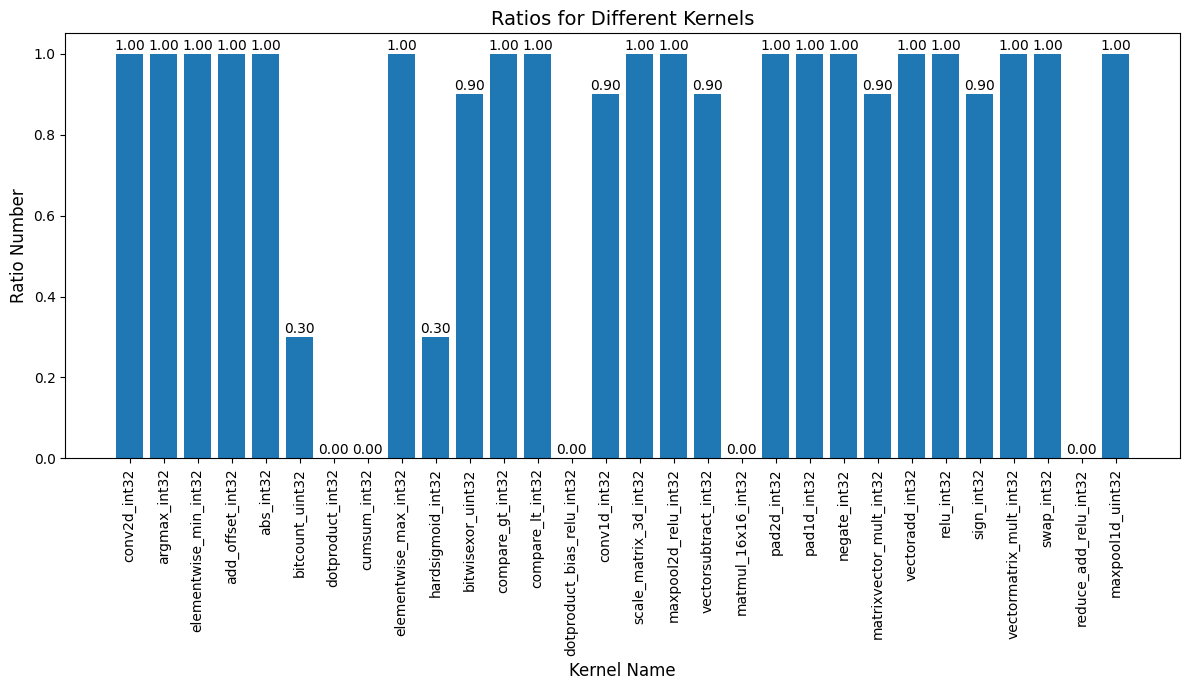

In [13]:
df_dynarapid_gpt_41_mini_k10 = pd.read_csv('dynarapid_gpt-4.1-mini_k10.csv')

kernel_dot_ratios = calculate_has_dot_per_kernel(df_dynarapid_gpt_41_mini_k10, 10, "pass@k")
kernel_dcp_ratios = calculate_has_dcp_per_kernel(df_dynarapid_gpt_41_mini_k10, 10, "pass@k")

df = pd.Series(kernel_dot_ratios).to_frame(name='Ratio')
df.index.name = 'Kernel'
df = df.reset_index()


# print("DataFrame from dictionary:")
# print(df)
# print("\n" + "="*30 + "\n")

# Create the comparison plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot both sets of points
ax.bar(df['Kernel'], df['Ratio'])
# ax.bar(df2['Kernel'], df2['Ratio'])

ax.set_xlabel("Kernel Name", fontsize=12)
ax.set_ylabel("Ratio Number", fontsize=12)
ax.set_title("Ratios for Different Kernels", fontsize=14)
ax.tick_params(axis='x', rotation=90) # Rotate x-axis labels for better fit

# Add the ratio values on top of each bar
for index, value in enumerate(df['Ratio']):
    ax.text(index, value + 0.01, f'{value:.2f}', ha='center')

# Improve layout and display the chart
plt.tight_layout()
plt.show()

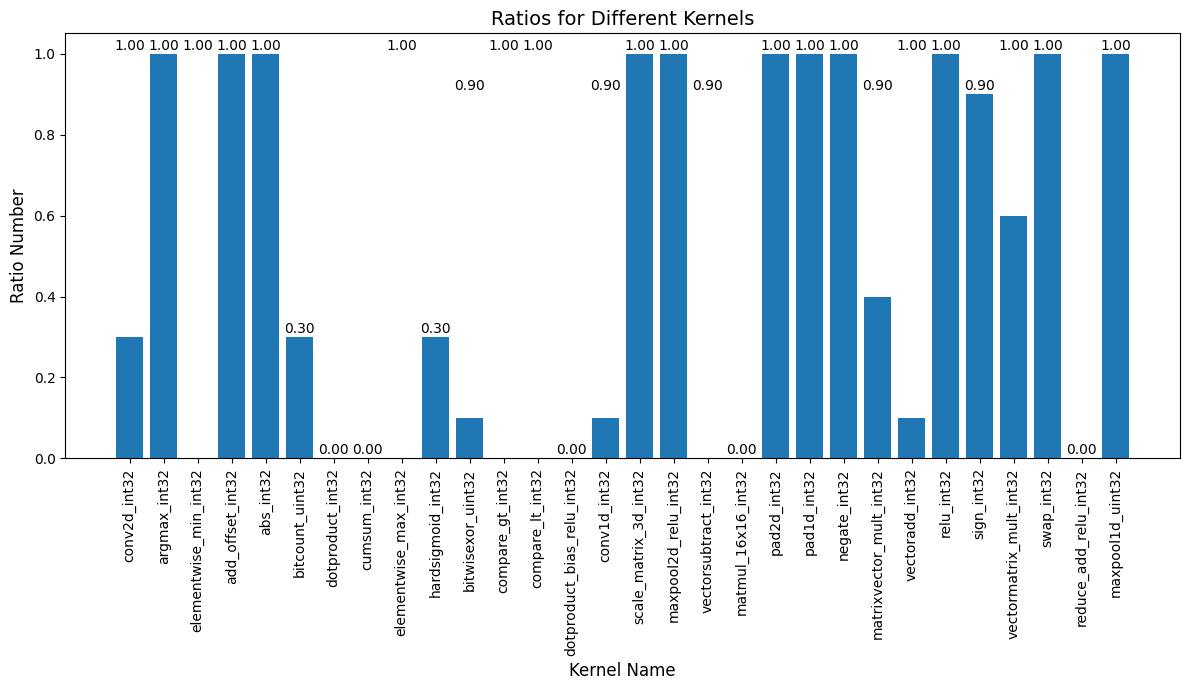

In [12]:
df2 = pd.Series(kernel_dcp_ratios).to_frame(name='Ratio')
df2.index.name = 'Kernel'
df2 = df2.reset_index()

fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(df2['Kernel'], df2['Ratio'])
ax.set_xlabel("Kernel Name", fontsize=12)
ax.set_ylabel("Ratio Number", fontsize=12)
ax.set_title("Ratios for Different Kernels", fontsize=14)
ax.tick_params(axis='x', rotation=90) # Rotate x-axis labels for better fit

# Add the ratio values on top of each bar
for index, value in enumerate(df['Ratio']):
    ax.text(index, value + 0.01, f'{value:.2f}', ha='center')

# Improve layout and display the chart
plt.tight_layout()
plt.show()